<a href="https://colab.research.google.com/github/Basharbalaa/chicago-food-inspections/blob/main/Chicago_food_inspections.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving food_inspections.csv to food_inspections.csv


In this dataset there's 102898 rows and 17 columns
The data covers from Jan 2021 to Nov 2026

In [2]:
import pandas as pd
df = pd.read_csv('food_inspections.csv')
df.shape

/tmp/ipykernel_449/2331984779.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('food_inspections.csv')


(102898, 17)

In [ ]:
df.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,2646390,VITASANA MARKET,VITASANA MARKET,3108989.0,NaN,Risk 1 (High),2 N RIVERSIDE PLZ,CHICAGO,IL,60606.0,11/05/2026,License,Not Ready,NaN,41.881977,-87.638876,"(41.88197704758362, -87.63887583987513)"
1,2646380,AMAZING LIGHTS INC.,AMAZING LIGHTS,3100334.0,NaN,Risk 1 (High),225 S CANAL ST,CHICAGO,IL,60606.0,11/05/2026,License,Not Ready,NaN,41.878531,-87.639427,"(41.878531278353606, -87.63942745962717)"
2,2646346,"THE AUSTIN OASIS, LLC",AUSTIN OASIS HEALTH CARE,2676957.0,Long Term Care,Risk 1 (High),901 S AUSTIN BLVD,CHICAGO,IL,60644.0,11/04/2026,Canvass,Fail,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",41.870347,-87.774129,"(41.87034652436215, -87.774128780491)"
3,2646302,THE NOOK DAYCARE UNITED LLC,THE NOOK CHILDCARE AND PRESCHOOL,2653246.0,Children's Services Facility,Risk 1 (High),2000-2006 W WARREN BLVD,CHICAGO,IL,60612.0,11/04/2026,Canvass Re-Inspection,Pass,"38. INSECTS, RODENTS, & ANIMALS NOT PRESENT - ...",41.882340,-87.676788,"(41.88233985932603, -87.67678798796877)"
4,2646366,MONSTER RAMEN,MONSTER RAMEN,2807487.0,Restaurant,Risk 1 (High),3435 W FULLERTON AVE,CHICAGO,IL,60647.0,11/04/2026,Non-Inspection,No Entry,NaN,41.924536,-87.713592,"(41.92453601837481, -87.71359208771081)"


In [ ]:
df.columns

Index(['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type',
       'Risk', 'Address', 'City', 'State', 'Zip', 'Inspection Date',
       'Inspection Type', 'Results', 'Violations', 'Latitude', 'Longitude',
       'Location'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102898 entries, 0 to 102897
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    102898 non-null  object 
 1   DBA Name         102893 non-null  object 
 2   AKA Name         102767 non-null  object 
 3   License #        102890 non-null  float64
 4   Facility Type    102375 non-null  object 
 5   Risk             102871 non-null  object 
 6   Address          102893 non-null  object 
 7   City             102812 non-null  object 
 8   State            102854 non-null  object 
 9   Zip              102885 non-null  float64
 10  Inspection Date  102893 non-null  object 
 11  Inspection Type  102893 non-null  object 
 12  Results          102893 non-null  object 
 13  Violations       70519 non-null   object 
 14  Latitude         102526 non-null  float64
 15  Longitude        102526 non-null  float64
 16  Location         102526 non-null  obje

The column with alot of missing values are violations 32379 Facility type 523. latitude, longitude, locations 372 respectively and finally AKA Name 131

One thing that surprises me in this dataset is when i checked the results for each year I realise that between each year we can find an increase in the number of inspections for over 1000 but from 2024 to 2025 the difference decreases by 23

In [ ]:
df.isnull().sum()

,0
Inspection ID,0
DBA Name,5
AKA Name,131
License #,8
Facility Type,523
Risk,27
Address,5
City,86
State,44
Zip,13


In [ ]:
df["Results"].value_counts()

,count
Results,
Pass,52027
Fail,19701
Pass w/ Conditions,14540
Out of Business,7281
No Entry,6951
Not Ready,2369
Business Not Located,24


In [ ]:
df["Inspection Type"].value_counts().head(10)

,count
Inspection Type,
Canvass,49661
License,14401
Canvass Re-Inspection,12633
Complaint,10315
Non-Inspection,5591
Complaint Re-Inspection,4521
License Re-Inspection,3268
Short Form Complaint,2109
Recent Inspection,178


In [ ]:
df["Facility Type"].value_counts().head(10)

,count
Facility Type,
Restaurant,72497
Grocery Store,9833
School,6653
Children's Services Facility,3663
Daycare Above and Under 2 Years,1547
Bakery,1403
Long Term Care,1000
Daycare (2 - 6 Years),667
Mobile Food Preparer,650


In [ ]:
df["Risk"].value_counts()

,count
Risk,
Risk 1 (High),82777
Risk 2 (Medium),14877
Risk 3 (Low),5153
All,64


In [5]:
df["Inspection Date"]=pd.to_datetime(df["Inspection Date"])
print(df["Inspection Date"].min())
print(df["Inspection Date"].max())

2021-01-11 00:00:00
2026-11-05 00:00:00


In [6]:
df["Inspection Date"].dt.year.value_counts().sort_index()

,count
Inspection Date,
2021.0,15559
2022.0,16936
2023.0,18261
2024.0,19228
2025.0,19205
2026.0,13704


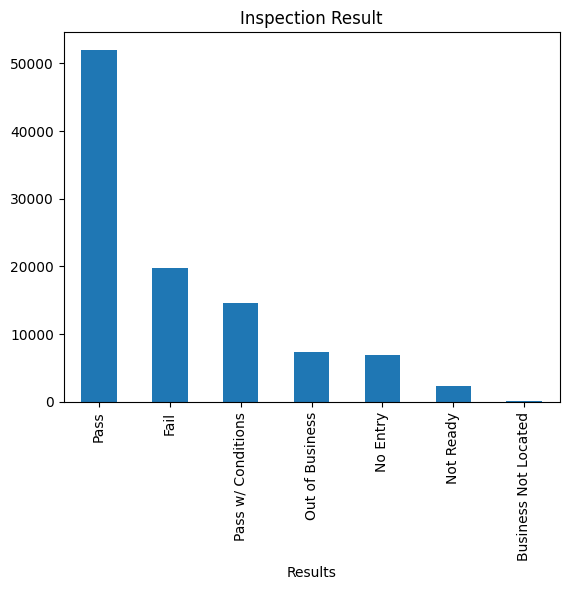

In [9]:
import matplotlib.pyplot as plt
df["Results"].value_counts().plot(kind="bar")
plt.title("Inspection Result")
plt.show()

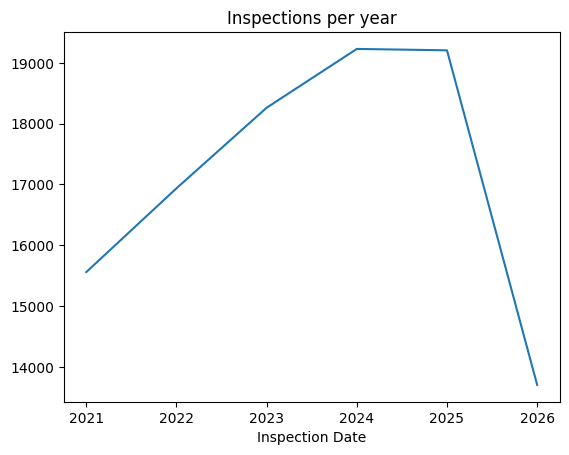

In [10]:
df["Inspection Date"].dt.year.value_counts().sort_index().plot(kind="line")
plt.title("Inspections per year")
plt.show()

In [11]:
df[df["Results"].isnull()]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
102893,{,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102894,"""error"" : true",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102895,"""message"" : ""Internal error""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102896,"""status"" : 500",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102897,},NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df["Violations"].isnull().groupby(df["Results"]).mean()

,Violations
Results,
Business Not Located,1.000000
Fail,0.024212
No Entry,0.966336
Not Ready,0.991980
Out of Business,0.998352
Pass,0.291137
Pass w/ Conditions,0.026823


In [13]:
df["Year"] = df["Inspection Date"].dt.year
pd.crosstab(df["Year"], df["Results"], normalize="index").round(3)

Results,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions
Year,,,,,,,
2021.0,0.0,0.191,0.070,0.023,0.079,0.437,0.201
2022.0,0.0,0.210,0.061,0.020,0.075,0.486,0.148
2023.0,0.0,0.210,0.064,0.021,0.071,0.505,0.129
2024.0,0.0,0.181,0.072,0.021,0.075,0.515,0.136
2025.0,0.0,0.177,0.074,0.023,0.067,0.541,0.119
2026.0,0.0,0.180,0.064,0.033,0.055,0.545,0.122
